In [117]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

# Data Cleaning

In [118]:
# load datasets, skipping extra rows at top
matad = pd.read_excel('original_MATA-D_v9.xlsx', skiprows=3)
matad_qualitative = pd.read_csv('CMPU-250 Group Project MATA-D - Qualitative.csv', skiprows=3)

In [119]:
matad_og = matad.copy()
matad_qualitative = matad_qualitative.copy()

In [120]:
matad.head()

,INCIDENT ID,INDUSTRY,LOCATION,YEAR,Wrong Time,Wrong Type,Wrong Object,Wrong Place,Observation Missed,False Observation,...,Temperature,Sound,Humidity,Illumination,Other,Adverse ambient conditions,Excessive demand,Inadequate work place layout,Inadequate team support,Irregular working hours
0,1,UPSTREAM,Piper Alpha,1988,1.0,1.0,NaN,NaN,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN
1,2,PETROCHEMICALS,Pasadena,1989,1.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,UPSTREAM,Ekofisk,2009,1.0,1.0,NaN,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
3,4,UPSTREAM,South Pass Block,1989,1.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,UPSTREAM,Sleipner,1991,NaN,1.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [121]:
matad.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 238 entries, 0 to 237
Data columns (total 57 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   INCIDENT ID                   238 non-null    int64  
 1   INDUSTRY                      238 non-null    object 
 2   LOCATION                      238 non-null    object 
 3   YEAR                          238 non-null    object 
 4   Wrong Time                    35 non-null     float64
 5   Wrong Type                    28 non-null     float64
 6   Wrong Object                  6 non-null      float64
 7   Wrong Place                   75 non-null     float64
 8   Observation Missed            37 non-null     float64
 9   False Observation             8 non-null      float64
 10  Wrong Identification          6 non-null      float64
 11  Faulty diagnosis              31 non-null     float64
 12  Wrong reasoning               27 non-null     float64
 13  Decis

In [122]:
matad_qualitative.head()

,INCIDENT ID,INDUSTRY,LOCATION,YEAR,Wrong Time,Wrong Type,Wrong Object,Wrong Place,Observation Missed,False Observation,...,Illumination,Other,Adverse ambient conditions,Excessive demand,Inadequate work place layout,Inadequate team support,Irregular working hours,Unnamed: 57,Unnamed: 58,BLAME
0,1,UPSTREAM,Piper Alpha,1988,"Moura, Raphael:\nTiming (Too early): Started M...","Moura, Raphael:\nToo little force (torque) or ...",NaN,NaN,"Moura, Raphael:\noverlook cue/signal: not real...",NaN,...,NaN,NaN,NaN,NaN,"Moura, Raphael:\nWrong position of quarters, c...",NaN,NaN,NaN,NaN,2
1,2,PETROCHEMICALS,Pasadena,1989,"Moura, Raphael:\nTiming (Too early): lockout s...",NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
2,3,UPSTREAM,Ekofisk,2009,"Moura, Raphael:\n1) Omission: Duty officer for...","Moura, Raphael:\nSpeed: vessel manoeuvred too ...",NaN,"Moura, Raphael:\nSequence (jump forward): duty...","Moura, Raphael:\n1) overlook measurement: duty...","Moura, Raphael:\nFalse recognition: event (man...",...,NaN,NaN,NaN,NaN,NaN,NaN,"Moura, Raphael:\nresting time regulations were...",NaN,NaN,1
3,4,UPSTREAM,South Pass Block,1989,"Moura, Raphael:\n1) duration too long: cutting...",NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
4,5,UPSTREAM,Sleipner,1991,NaN,"Moura, Raphael:\nEntered wrong input parameter...",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2


In [123]:
matad_qualitative.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 238 entries, 0 to 237
Data columns (total 60 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   INCIDENT ID                   238 non-null    int64  
 1   INDUSTRY                      238 non-null    object 
 2   LOCATION                      238 non-null    object 
 3   YEAR                          238 non-null    object 
 4   Wrong Time                    35 non-null     object 
 5   Wrong Type                    28 non-null     object 
 6   Wrong Object                  6 non-null      object 
 7   Wrong Place                   75 non-null     object 
 8   Observation Missed            37 non-null     object 
 9   False Observation             8 non-null      object 
 10  Wrong Identification          6 non-null      object 
 11  Faulty diagnosis              31 non-null     object 
 12  Wrong reasoning               27 non-null     object 
 13  Decis

In [124]:
# sum errors by type and save to new columns
matad['Human Errors'] = matad.iloc[:, 4:29].apply(lambda x: x.sum(), axis=1)
matad['Machine Errors'] = matad.iloc[:, 29:37].apply(lambda x: x.sum(), axis=1)
matad['Organization Errors'] = matad.iloc[:, 37:57].apply(lambda x: x.sum(), axis=1)

# add column for proportion of human errors
matad['Human Error Proportion'] = matad['Human Errors'] / (matad['Human Errors'] + matad['Machine Errors'] + matad['Organization Errors'])

# add blame column from qualitative dataset
matad['Blame'] = matad_qualitative['BLAME']

In [125]:
# remove extra columns
columns_to_keep = matad.columns[:4].to_list() + matad.columns[-5:].to_list()

matad = matad[columns_to_keep]

In [126]:
# make headers and industry column title case
matad.rename(str.title, axis='columns', inplace=True)
matad['Industry'] = matad['Industry'].str.title()

matad.head()

,Incident Id,Industry,Location,Year,Human Errors,Machine Errors,Organization Errors,Human Error Proportion,Blame
0,1,Upstream,Piper Alpha,1988,7.0,2.0,10.0,0.368421,2
1,2,Petrochemicals,Pasadena,1989,3.0,1.0,5.0,0.333333,2
2,3,Upstream,Ekofisk,2009,8.0,0.0,5.0,0.615385,1
3,4,Upstream,South Pass Block,1989,4.0,1.0,3.0,0.500000,3
4,5,Upstream,Sleipner,1991,2.0,1.0,3.0,0.333333,2


In [127]:
# remove datapoints without known year
matad = matad[matad['Year'] != '?']
# remove datapoints with no error assigned to any of 3 types (blame = 0)
matad = matad[matad['Blame'] != 0]

matad.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 231 entries, 0 to 237
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Incident Id             231 non-null    int64  
 1   Industry                231 non-null    object 
 2   Location                231 non-null    object 
 3   Year                    231 non-null    object 
 4   Human Errors            231 non-null    float64
 5   Machine Errors          231 non-null    float64
 6   Organization Errors     231 non-null    float64
 7   Human Error Proportion  231 non-null    float64
 8   Blame                   231 non-null    int64  
dtypes: float64(4), int64(2), object(3)
memory usage: 18.0+ KB


In [128]:
matad.dtypes

Incident Id                 int64
Industry                   object
Location                   object
Year                       object
Human Errors              float64
Machine Errors            float64
Organization Errors       float64
Human Error Proportion    float64
Blame                       int64
dtype: object

In [129]:
# change datatype of year and error columns to int
matad[['Year', 'Human Errors', 'Machine Errors', 'Organization Errors']] = matad[['Year', 'Human Errors', 'Machine Errors', 'Organization Errors']].astype(int, errors='raise')

matad.dtypes

Incident Id                 int64
Industry                   object
Location                   object
Year                        int64
Human Errors                int64
Machine Errors              int64
Organization Errors         int64
Human Error Proportion    float64
Blame                       int64
dtype: object

In [130]:
# export dataset
matad.to_csv('clean_MATA-D_v9.csv', index=False)

# Exploratory Analysis

## Summary Statistics

In [131]:
matad['Year'].describe()

count     231.000000
mean     1996.225108
std        14.350321
min      1953.000000
25%      1988.500000
50%      2001.000000
75%      2007.000000
max      2013.000000
Name: Year, dtype: float64

In [132]:
matad['Human Error Proportion'].describe()

count    231.000000
mean       0.199731
std        0.205052
min        0.000000
25%        0.000000
50%        0.200000
75%        0.333333
max        1.000000
Name: Human Error Proportion, dtype: float64

In [133]:
matad['Industry'].describe()

count          231
unique          31
top       Refinery
freq            37
Name: Industry, dtype: object

## Data Visualizations

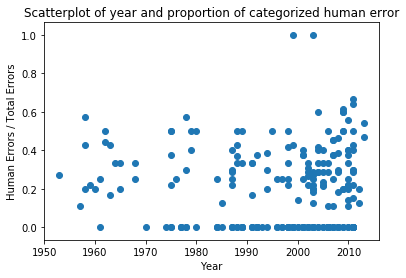

In [134]:
plt.scatter(x=matad['Year'], y=matad['Human Error Proportion'])
plt.title('Scatterplot of year and proportion of categorized human error')
plt.xlabel('Year')
plt.ylabel('Human Errors / Total Errors')
plt.savefig('figures/year_error.png')
plt.show()

![Scatter plot. Refer to image description below.](figures/year_error.png)

**Figure 1.** This is a scatter plot that shows the relationship between the year of an incident and the proportion of human over total errors, as categorized by the MATA-D dataset. The x-axis is labelled Year and ranges from 1950 to 2010, in increments of 10. The y-axis is labelled Human Errors/Total Errors and ranges from 0.0 to 1.0 in increments of 0.2. There are 231 data points plotted on the graph, with points with identical values overlapping. The data points increase in concentration from left to right, with most points from 1990 or later. Many points have a human error proportion of 0.0, while only two points have a human error proportion of 1.0. There is no clear positive or negative pattern over time.

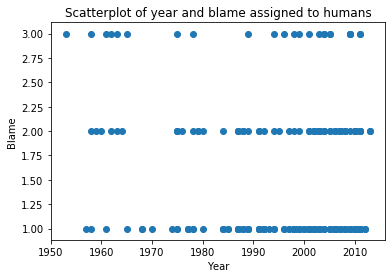

In [135]:
plt.scatter(x=matad['Year'], y=matad['Blame'])
plt.title('Scatterplot of year and blame assigned to humans')
plt.xlabel('Year')
plt.ylabel('Blame')
plt.savefig('figures/year_blame.png')
plt.show()

![Scatter plot. Refer to image description below.](figures/year_blame.png)

**Figure 2.** This is a scatter plot that shows the relationship between the year of an incident and the blame assigned to humans. The x-axis is labelled Year and ranges from 1950 to 2010, in increments of 10. The y-axis is labelled Blame and ranges from 1.00 to 3.00, in increments of 0.25, but blame only takes the values 1, 2 and 3, so the points form three horizontal rows. There are 231 data points plotted on the graph, with points with identical values overlapping.

The data points increase in concentration from left to right, with most points from 1990 or later. Of the three rows of blame ratings, the bottommost (blame of 1.0) has the most points. None of the three blame ratings show any clear change over time.

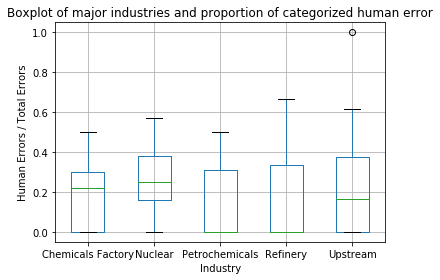

In [136]:
# filter by top 5 most common industries in dataset for readability
major_industries = matad['Industry'].value_counts().index[:5]
matad_major_industries = matad[matad['Industry'].isin(major_industries)]

matad_major_industries.boxplot(column='Human Error Proportion', by='Industry')
plt.title('Boxplot of major industries and proportion of categorized human error')
plt.xlabel('Industry')
plt.ylabel('Human Errors / Total Errors')
plt.tight_layout()
plt.suptitle('')
plt.savefig('figures/industry_error.png')
plt.show()

![Box plot. Refer to image description below.](figures/industry_error.png)

**Figure 3.** This is a box plot that shows the distribution of the proportion of categorized human error for the five industries with the most incidents. The x-axis is labelled Industry and shows the industries Chemicals Factory, Nuclear, Petrochemicals, Refinery and Upstream, from left to right. The y-axis is labelled Human Errors/Total Errors and ranges from 0.0 to 1.0, in increments of 0.2. The medians are approximately 0.22 for Chemicals Factory, 0.25 for Nuclear, 0 for Petrochemicals, 0 for Refinery and 0.17 for Upstream. The upper whiskers reach approximately 0.5 to 0.67, and Upstream has one outlier at 1.0. The boxes overlap widely across the industries.

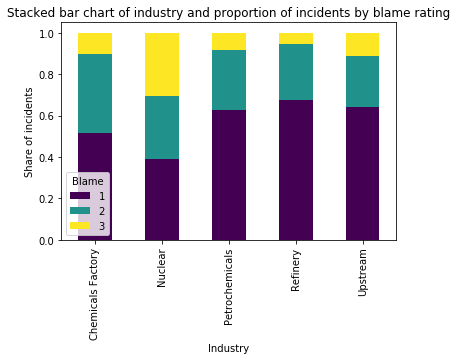

In [137]:
pd.crosstab(matad_major_industries['Industry'], matad_major_industries['Blame'], normalize='index').plot(
    kind='bar', stacked=True, colormap='viridis')
plt.title('Stacked bar chart of industry and proportion of incidents by blame rating')
plt.ylabel('Share of incidents')
plt.legend(title='Blame')
plt.savefig('figures/industry_blame.png')
plt.show()

![Stacked bar graph. Refer to image description below.](figures/industry_blame.png)

**Figure 4.** This is a bar graph that shows the proportion of incidents at each blame rating for the five industries with the most incidents. The proportions vary for different industries. The data is summarized in the following table:

In [138]:
pd.crosstab(matad_major_industries['Industry'], matad_major_industries['Blame'], normalize='index').round(2)

Blame,1,2,3
Industry,,,
Chemicals Factory,0.52,0.38,0.10
Nuclear,0.39,0.30,0.30
Petrochemicals,0.62,0.29,0.08
Refinery,0.68,0.27,0.05
Upstream,0.64,0.25,0.11


**Table 1.** Proportion of incidents at each blame rating, by industry for the five industries with the most incidents.

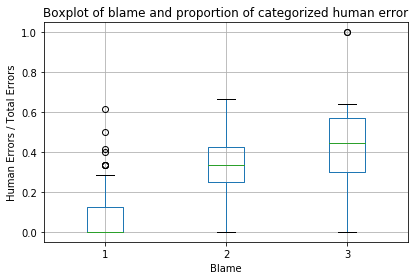

In [139]:
matad.boxplot(column='Human Error Proportion', by='Blame')
plt.title('Boxplot of blame and proportion of categorized human error')
plt.xlabel('Blame')
plt.ylabel('Human Errors / Total Errors')
plt.tight_layout()
plt.suptitle('')
plt.savefig('figures/error_blame.png')
plt.show()

![Box plot. Refer to image description below.](figures/blame_boxplot.png)

**Figure 6.** This is a box plot that shows the distribution of the proportion of categorized human error at each blame rating. The x-axis is labelled Blame and shows the ratings 1, 2 and 3. The y-axis is labelled Human Errors / Total Errors and ranges from 0.0 to 1.0, in increments of 0.2. The median proportion increases with blame rating, at 0 for blame rating 1, approximately 0.33 for blame rating 2 and approximately 0.44 for blame rating 3. Blame rating 1 has 6 outliers with error proportions of approximately 0.28 to 0.61 Blame rating 3 has one outlier at 1.0.